# B01-DB — DBSCAN trên RFM (log1p + Standard + PCA 90%)

Thí nghiệm **B01-DB** (người chạy: An) theo chiến lược model. So với A01, **thêm `log1p` trước khi chuẩn hóa**: làm sạch → RFM → `log1p` → StandardScaler → PCA giữ ≥ 90% phương sai → DBSCAN. Đây là nhánh chính của nhóm B cho DBSCAN; B02-GN, B03-KM (của An) và B04 so với B01.

Pipeline `log1p` dùng đúng cách B01-GN (Nguyên) đã làm cho GMM, để ba mô hình B01 so sánh được với nhau.

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary"]
PCA_VAR = 0.90                      # giống A01-DB, B01-GN
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]     # giống A01-DB
EPS_GRID = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]  # mở rộng vùng nhỏ vì log1p co khoảng cách lại
MAX_NOISE = 0.05                    # điều kiện chọn: nhiễu tối đa 5% số khách — giống A01-DB
MIN_CLUSTERS = 2                    # điều kiện chọn: ít nhất 2 cụm (không tính nhiễu) — giống A01-DB

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01-DB, A02-KM, A02-GN, A03-KM, A04-DB)
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figure"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** Cùng 4.327 khách, cùng file feature chung đã dùng cho A01-DB, A02-KM, A02-GN, A03-KM, A04-DB.

## log1p rồi chuẩn hóa, PCA giữ 90% phương sai

Thay đổi duy nhất so với A01-DB: thêm `log1p` trước `StandardScaler`.

In [3]:
skew = pd.DataFrame({"skew_raw": X.skew(), "skew_log1p": np.log1p(X).skew()}).round(2)
print(skew)

X_scaled = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())]).fit_transform(X)
cum = np.cumsum(PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
pca = PCA(n_components=n_pc, svd_solver="full").fit(X_scaled)
Z = pca.transform(X_scaled)
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")

           skew_raw  skew_log1p
Recency        1.25       -0.33
Frequency     11.95        1.21
Monetary      21.04        0.35
Phương sai tích lũy: [0.7536 0.9401 1.    ]
Số PC giữ lại: 2 / 3 (phương sai giữ 94.01%)


**Nhận xét:** `log1p` kéo Monetary từ lệch cực mạnh (skew 21,04) về gần đối xứng (0,35), Recency về lệch trái nhẹ (−0,33); Frequency còn lệch (1,21) vì nhiều khách chỉ mua đúng 1 lần. Sau log1p, PCA 90% chỉ cần **2/3 PC** (giữ 94,01%) — khác hẳn A01-DB (phải giữ đủ 3/3 PC). Đây là lần đầu trong nhóm A/B, PCA thực sự giảm chiều trước khi đưa vào DBSCAN.

## Chọn eps bằng đồ thị k-distance

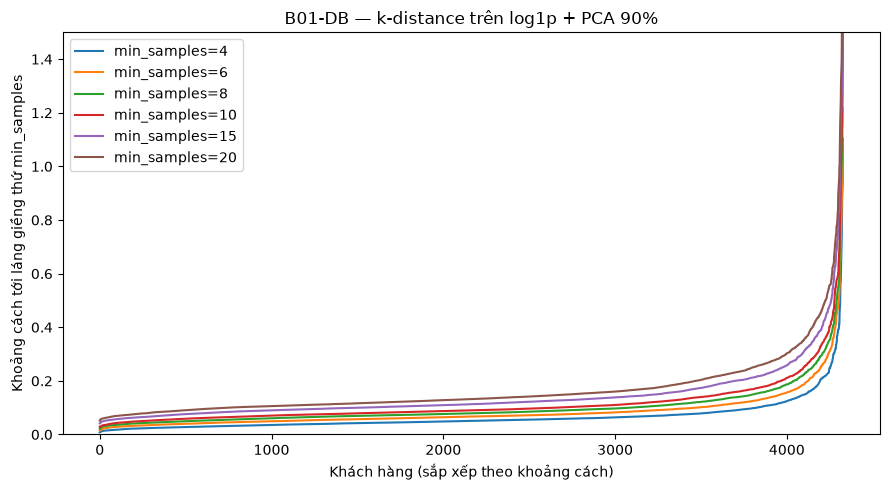

,4,6,8,10,15,20
P50,0.051,0.067,0.079,0.090,0.113,0.132
P90,0.108,0.137,0.162,0.183,0.228,0.269
P95,0.151,0.194,0.230,0.258,0.317,0.361
P99,0.320,0.401,0.453,0.547,0.630,0.722


In [4]:
kdist = {}
for ms in MIN_SAMPLES_GRID:
    d = NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)[0][:, -1]
    kdist[ms] = np.sort(d)

fig, ax = plt.subplots(figsize=(9, 5))
for ms, d in kdist.items():
    ax.plot(d, label=f"min_samples={ms}")
ax.set_ylim(0, 1.5)
ax.set_xlabel("Khách hàng (sắp xếp theo khoảng cách)")
ax.set_ylabel("Khoảng cách tới láng giềng thứ min_samples")
ax.set_title("B01-DB — k-distance trên log1p + PCA 90%")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "k_distance.png", dpi=150); plt.show()

pd.DataFrame({ms: np.quantile(d, [0.5, 0.9, 0.95, 0.99]) for ms, d in kdist.items()},
             index=["P50", "P90", "P95", "P99"]).round(3)

**Nhận xét:** Khoảng cách nhỏ hơn hẳn A01-DB (P95 chỉ 0,15–0,36 so với 0,17–0,33, nhưng P99 co lại mạnh: 0,32–0,72 so với 0,74–1,44 của A01-DB) vì log1p đã nén bớt các khách Monetary cực lớn. Không có khuỷu rõ ràng, vẫn cần quét lưới rộng.

## Quét lưới eps × min_samples

In [5]:
def run_dbscan(eps, ms):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
    mask = labels != -1
    sizes = pd.Series(labels[mask]).value_counts()
    k = len(sizes)
    row = {"min_samples": ms, "eps": eps, "n_clusters": k,
           "noise_pct": round(100 * (~mask).mean(), 2),
           "largest_pct": round(100 * sizes.iloc[0] / len(Z), 2) if k else np.nan,
           "smallest": int(sizes.iloc[-1]) if k else 0,
           "silhouette": np.nan, "dbi": np.nan}
    if k >= 2:
        row["silhouette"] = round(silhouette_score(Z[mask], labels[mask]), 4)
        row["dbi"] = round(davies_bouldin_score(Z[mask], labels[mask]), 4)
    return row

grid = pd.DataFrame([run_dbscan(e, m) for m in MIN_SAMPLES_GRID for e in EPS_GRID])
print("Số cấu hình đã chạy:", len(grid))
print("Số cấu hình có >= 2 cụm:", int((grid["n_clusters"] >= 2).sum()))
grid[grid["n_clusters"] >= 2].sort_values("silhouette", ascending=False).head(10)

Số cấu hình đã chạy: 72
Số cấu hình có >= 2 cụm: 34


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
7,4,0.50,2,0.18,99.68,6,0.6579,0.2753
48,15,0.05,3,97.90,1.29,16,0.6116,0.4019
17,6,0.30,2,1.06,98.80,6,0.5861,0.3044
30,8,0.40,2,0.58,99.24,8,0.5854,0.3112
5,4,0.30,2,0.81,98.96,10,0.5842,0.3210
18,6,0.40,2,0.53,99.24,10,0.5818,0.3223
31,8,0.50,2,0.42,99.33,11,0.5803,0.3306
39,10,0.20,2,5.15,94.59,11,0.4909,0.3558
40,10,0.25,2,3.05,96.74,9,0.4852,0.3631
16,6,0.25,3,1.87,97.85,6,0.4843,0.3473


**Nhận xét:** 34/72 cấu hình có ≥ 2 cụm (gấp đôi tỷ lệ của A01-DB là 14/54), nhưng top 10 theo Silhouette vẫn đều có một cụm chiếm ≥ 94,6% khách — vẫn là tách ngoại lai, chưa phải chia cân đối.

## Chọn cấu hình

Cùng quy tắc A01-DB: ≥ 2 cụm, nhiễu ≤ 5% số khách, chọn Silhouette cao nhất.

In [6]:
valid = grid[(grid["n_clusters"] >= MIN_CLUSTERS) & (grid["noise_pct"] <= MAX_NOISE * 100)]
best = valid.sort_values("silhouette", ascending=False).iloc[0]
print("Cấu hình được chọn:")
print(best.to_string())

labels = DBSCAN(eps=best["eps"], min_samples=int(best["min_samples"])).fit_predict(Z)

Cấu hình được chọn:
min_samples     4.0000
eps             0.5000
n_clusters      2.0000
noise_pct       0.1800
largest_pct    99.6800
smallest        6.0000
silhouette      0.6579
dbi             0.2753


**Nhận xét:** Chọn `eps=0,5`, `min_samples=4`: 2 cụm, nhiễu 0,18% (8 khách), Silhouette 0,6579, DBI 0,2753 — thấp hơn Silhouette của A01-DB (0,8177) nhưng DBI tốt hơn (0,2753 so với 0,4046).

## Đối chiếu A01-DB

Dựng lại A01-DB (RFM thô, không log1p) ngay tại đây để so bằng ARI, không chép số từ notebook khác.

In [7]:
X_scaled_a01 = StandardScaler().fit_transform(X)
cum_a01 = np.cumsum(PCA(svd_solver="full").fit(X_scaled_a01).explained_variance_ratio_)
n_pc_a01 = int(np.searchsorted(cum_a01, PCA_VAR) + 1)
Z_a01 = PCA(n_components=n_pc_a01, svd_solver="full").fit_transform(X_scaled_a01)
labels_a01 = DBSCAN(eps=1.5, min_samples=4).fit_predict(Z_a01)   # cấu hình A01-DB đã chọn (An, 16-11-2026)

print("Số PC: B01 =", Z.shape[1], "| A01 =", Z_a01.shape[1])
print("ARI (B01-DB vs A01-DB, kể cả nhãn nhiễu):", round(adjusted_rand_score(labels, labels_a01), 4))
print("B01-DB: n_clusters =", int(best["n_clusters"]), "| noise% =", best["noise_pct"])
print("A01-DB: n_clusters =", len(set(labels_a01)) - (1 if -1 in labels_a01 else 0),
      "| noise% =", round(100 * (labels_a01 == -1).mean(), 2))

Số PC: B01 = 2 | A01 = 3
ARI (B01-DB vs A01-DB, kể cả nhãn nhiễu): 0.5966
B01-DB: n_clusters = 2 | noise% = 0.18
A01-DB: n_clusters = 3 | noise% = 0.42


**Nhận xét:** `log1p` làm thay đổi thật sự: PCA giữ 2 PC thay vì 3 (không còn là phép xoay thuần túy như A02/A04 so với A01), và ARI giữa B01-DB và A01-DB chỉ **0,5966** — khác biệt rõ rệt, không phải 'tương đương' như các biến thể A. Số cụm và tỷ lệ nhiễu cũng khác (2 so với 3 cụm, 0,18% so với 0,42% nhiễu).

## Hồ sơ cụm

In [8]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"),
    Frequency=("Frequency", "median"), Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof.drop(columns="Monetary_sum").round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
-1,8,32.0,40.0,94634.1,0.2,7.7
0,4313,51.0,2.0,657.2,99.7,83.6
1,6,1.5,94.0,59697.4,0.1,8.7


**Nhận xét:** Cụm 0 (4.313 khách, 99,7%) là khách phổ thông (Frequency 2, Monetary 657). Cụm 1 (6 khách) là VIP cực đoan: Recency 1,5 ngày, Frequency 94, Monetary 59.697 — chiếm 8,7% Monetary dù chỉ 0,1% khách. Nhóm nhiễu (8 khách, 0,2%) cũng chi tiêu rất cao (Monetary trung vị 94.634), chiếm 7,7% Monetary. Vẫn là tách outlier, nhưng ranh giới mịn hơn A01-DB (3 nhóm nhỏ khác nhau thay vì gộp chung).

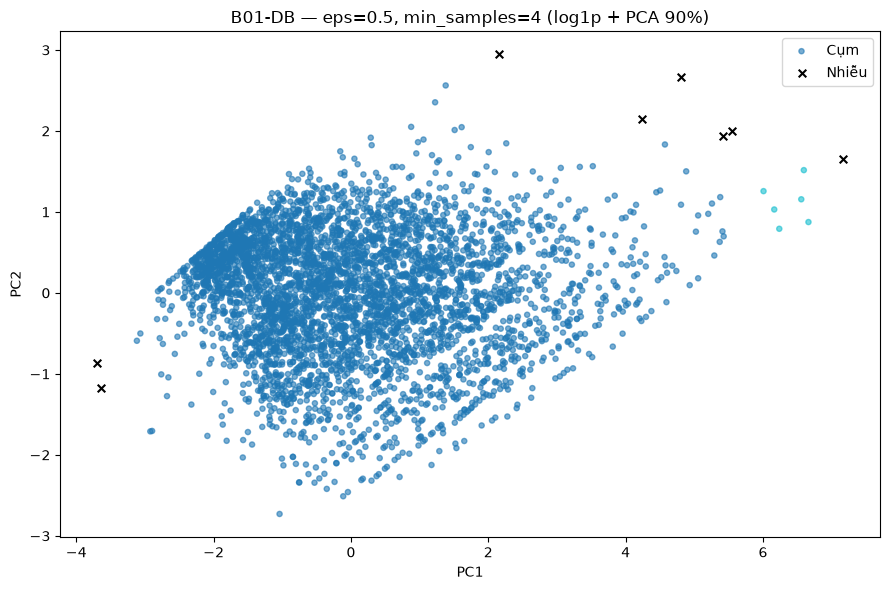

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
noise = labels == -1
ax.scatter(Z[~noise, 0], Z[~noise, 1], c=labels[~noise], cmap="tab10", s=14, alpha=0.6, label="Cụm")
ax.scatter(Z[noise, 0], Z[noise, 1], c="black", marker="x", s=30, label="Nhiễu")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"B01-DB — eps={best['eps']}, min_samples={int(best['min_samples'])} (log1p + PCA 90%)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Hình vẫn cho thấy một khối lớn và vài điểm ngoại lai, nhưng khối chính co gọn hơn (không kéo dài hình chữ V như A01-DB) vì log1p đã làm phân phối RFM cân đối hơn trước khi PCA.

## Lưu kết quả

In [10]:
grid.to_csv(OUT / "dbscan_b01_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_b01_labels.csv", index=False)
params = {"experiment": "B01-DB", "features": FEATURES, "transform": "log1p", "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]),
          "n_clusters": int(best["n_clusters"]), "noise_pct": float(best["noise_pct"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"]),
          "ari_vs_a01_db": float(adjusted_rand_score(labels, labels_a01))}
json.dump(params, open(OUT / "dbscan_b01_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_b01_grid.csv', 'dbscan_b01_labels.csv', 'dbscan_b01_params.json']


**Nhận xét kết luận B01-DB:** `log1p` làm thay đổi thật (PCA giảm chiều thật, ARI chỉ 0,60 so với A01-DB) nhưng **chưa giải quyết được vấn đề cốt lõi**: DBSCAN vẫn chọn ra cấu hình chỉ tách một nhóm VIP cực nhỏ (6 khách, 0,1%) khỏi khối phổ thông, giống kết luận ở A01-DB/A02-KM/A04-DB. Khác với B01-GN (GMM trên cùng log1p+PCA90% cho 4 cụm cân đối 838–1.509 khách), DBSCAN dựa trên khoảng cách vẫn thiên về tách outlier dù đã log1p. Gợi ý: B02/B03/B04 (biến đổi R,F,M khác hoặc scaler khác) hoặc chuyển hẳn sang GMM/K-Means mới cho ra phân khúc cân đối trên dữ liệu RFM 3 biến này.